# Darth Netzhautus: Contrastive Learning for Rare Eye Diseases (mid-sprint prototype)
**ZEISS India Campus Hackathon (BeyondCode'26) | IIT Kanpur | solo entry**

**Idea:** build positive pairs for contrastive pretraining of a retinal encoder using **FACT-style Fourier amplitude mixing** (keep the image's phase, mix in another image's low-frequency amplitude), plus degradation views (illumination, defocus blur, noise).

**Status: early prototype.** Everything here is a small-scale run on RFMiD only (128 px, ResNet-18, short schedule). Evaluation is a binary `Disease_Risk` linear-probe proxy with a held-out split. Transfer to IDRiD and per-disease rare-class evaluation are next steps.

Run the cells top to bottom on a Colab T4 (Runtime > Run all). Set `DATA_DIR` in the first code cell.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/RFMiD_All_Classes_Dataset"          # <-- change if your RFMiD folder has another name
OUT_DIR  = "/content/drive/MyDrive/RFMiD_results"  # results are saved here
IMG, EPOCHS, BATCH, SEED = 128, 80, 128, 0

import os; os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load RFMiD and cache a small tensor

In [4]:
import glob, random, numpy as np, pandas as pd, torch
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

imgs = {}
for ext in ("png", "jpg", "jpeg", "PNG", "JPG"):
    for p in glob.glob(f"{DATA_DIR}/**/*.{ext}", recursive=True):
        imgs[os.path.splitext(os.path.basename(p))[0]] = p
print(len(imgs), "images found")

csv = None
cands = glob.glob(f"{DATA_DIR}/**/*.csv", recursive=True)
for p in sorted(cands, key=lambda s: "train" not in s.lower()):
    cols = pd.read_csv(p, nrows=1).columns
    if "ID" in cols and "Disease_Risk" in cols:
        csv = p; break
print("labels:", csv)

df = pd.read_csv(csv)
df = df[df.ID.astype(str).isin(imgs)].reset_index(drop=True)
print(len(df), "labeled images matched | disease fraction:", round(df.Disease_Risk.mean(), 3))

def load(i):
    return np.asarray(Image.open(imgs[str(i)]).convert("RGB").resize((IMG, IMG), Image.BILINEAR))

with ThreadPoolExecutor(8) as ex:
    arr = list(ex.map(load, df.ID))
X = torch.from_numpy(np.stack(arr)).permute(0, 3, 1, 2).contiguous()   # uint8 N,3,H,W
y = torch.tensor(df.Disease_Risk.values)
torch.save({"X": X, "y": y}, "/content/cache.pt")
print(X.shape)

1921 images found
labels: /content/drive/MyDrive/RFMiD_All_Classes_Dataset/2. Groundtruths/a. RFMiD_Training_Labels.csv
1920 labeled images matched | disease fraction: 0.791
torch.Size([1920, 3, 128, 128])


In [5]:
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X), generator=g)
n_te = int(0.2 * len(X))
te_idx, tr_idx = perm[:n_te], perm[n_te:]      # pretraining and probe-training use tr_idx only
Xg = X.to(dev)
print("train:", len(tr_idx), "test:", len(te_idx))

device: cuda
train: 1536 test: 384


## 2. Augmentations: FACT amplitude mixing, degradations, spatial

In [6]:
import torch.nn as nn, torch.nn.functional as F
import torchvision.transforms.v2 as T
import torchvision.transforms.v2.functional as TF

def fact_batch(x, ratio=0.15):
    """Keep each image's phase; mix a random partner's LOW-frequency amplitude into it (random strength per image)."""
    B = x.size(0)
    y_ = x[torch.randperm(B, device=x.device)]
    fx = torch.fft.fftshift(torch.fft.fft2(x), dim=(-2, -1))
    fy = torch.fft.fftshift(torch.fft.fft2(y_), dim=(-2, -1))
    ax, px, ay = fx.abs(), fx.angle(), fy.abs()
    H, W = x.shape[-2:]
    h, w = int(H * ratio), int(W * ratio)
    cy, cx = H // 2, W // 2
    lam = torch.rand(B, 1, 1, 1, device=x.device)
    a = ax.clone()
    sl = (Ellipsis, slice(cy - h, cy + h), slice(cx - w, cx + w))
    a[sl] = (1 - lam) * ax[sl] + lam * ay[sl]
    out = torch.fft.ifft2(torch.fft.ifftshift(a * torch.exp(1j * px), dim=(-2, -1))).real
    return out.clamp(0, 1)

def degrade(x):
    """Illumination change, defocus blur (on ~half the batch), sensor noise."""
    B, dv = x.size(0), x.device
    b = 1 + (torch.rand(B, 1, 1, 1, device=dv) - 0.5) * 0.6
    c = 1 + (torch.rand(B, 1, 1, 1, device=dv) - 0.5) * 0.6
    x = ((x - 0.5) * c + 0.5) * b
    s = random.uniform(0.5, 2.0)
    blurred = TF.gaussian_blur(x, [7, 7], [s, s])
    x = torch.where(torch.rand(B, 1, 1, 1, device=dv) < 0.5, blurred, x)
    x = x + torch.randn_like(x) * torch.rand(B, 1, 1, 1, device=dv) * 0.05
    return x.clamp(0, 1)

rrc = T.RandomResizedCrop(IMG, scale=(0.5, 1.0), antialias=True)
def spatial(x):
    out = torch.stack([rrc(xi) for xi in x])
    out = torch.where(torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5, out.flip(-1), out)
    out = torch.where(torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5, out.flip(-2), out)
    return out

def view(x, mode):
    if mode == "spatial":      # SimCLR-style baseline: spatial augmentation only
        return spatial(x)
    if mode == "fact":         # proposed: spatial + FACT + degradations
        return degrade(fact_batch(spatial(x)))
    raise ValueError(mode)

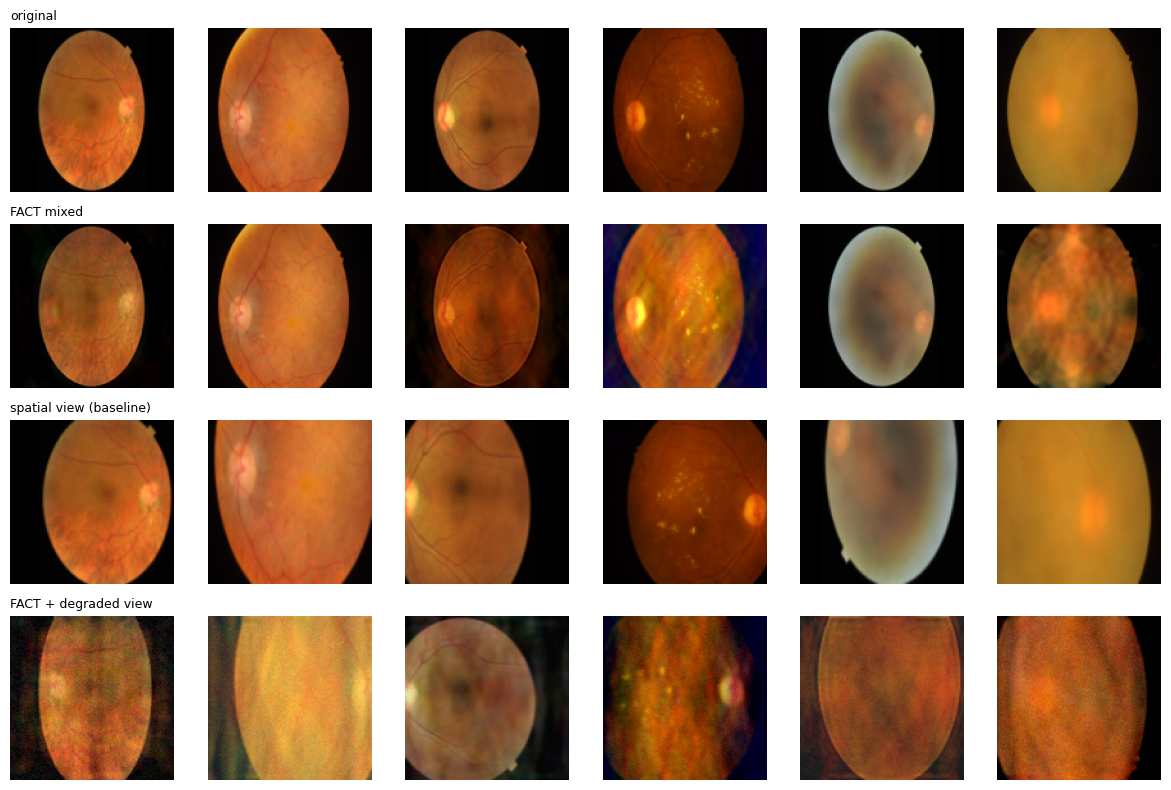

In [7]:
import matplotlib.pyplot as plt
x = Xg[tr_idx[:6]].float() / 255
rows = [("original", x), ("FACT mixed", fact_batch(x)), ("spatial view (baseline)", view(x, "spatial")), ("FACT + degraded view", view(x, "fact"))]
fig, ax = plt.subplots(len(rows), 6, figsize=(12, 2 * len(rows)))
for r, (name, t) in enumerate(rows):
    for c in range(6):
        ax[r, c].imshow(t[c].permute(1, 2, 0).cpu().clamp(0, 1)); ax[r, c].axis("off")
    ax[r, 0].set_title(name, fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fact_grid.png", dpi=130); plt.show()

## 3. SimCLR pretraining (baseline vs FACT) on the training split, no labels used

In [8]:
from torchvision.models import resnet18, ResNet18_Weights
import time

def nt_xent(z1, z2, t=0.2):
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = z @ z.T / t
    sim.fill_diagonal_(-1e9)
    n = z1.size(0)
    tgt = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, tgt)

def pretrain(mode):
    torch.manual_seed(SEED); random.seed(SEED)
    enc = resnet18(weights=None); enc.fc = nn.Identity()
    head = nn.Sequential(nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 128))
    enc.to(dev); head.to(dev)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(head.parameters()), lr=5e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))
    Xtr, losses, t0 = Xg[tr_idx], [], time.time()
    for ep in range(EPOCHS):
        enc.train(); head.train()
        p = torch.randperm(len(Xtr), device=dev)
        tot, nb = 0.0, 0
        for i in range(0, len(p) - BATCH + 1, BATCH):
            xb = Xtr[p[i:i + BATCH]].float() / 255
            with torch.no_grad():
                v1, v2 = view(xb, mode), view(xb, mode)
            with torch.autocast(dev, dtype=torch.float16, enabled=(dev == "cuda")):
                z1, z2 = head(enc(v1)), head(enc(v2))
            loss = nt_xent(z1.float(), z2.float())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); nb += 1
        sched.step(); losses.append(tot / nb)
        if ep % 5 == 0 or ep == EPOCHS - 1:
            print(f"[{mode}] epoch {ep+1}/{EPOCHS} loss {losses[-1]:.3f}  ({time.time()-t0:.0f}s)")
    torch.save(enc.state_dict(), f"{OUT_DIR}/enc_{mode}.pt")
    return enc, losses

enc_spatial, loss_spatial = pretrain("spatial")

[spatial] epoch 1/80 loss 3.608  (4s)
[spatial] epoch 6/80 loss 1.677  (15s)
[spatial] epoch 11/80 loss 1.464  (25s)
[spatial] epoch 16/80 loss 1.416  (36s)
[spatial] epoch 21/80 loss 1.371  (47s)
[spatial] epoch 26/80 loss 1.316  (58s)
[spatial] epoch 31/80 loss 1.306  (68s)
[spatial] epoch 36/80 loss 1.276  (79s)
[spatial] epoch 41/80 loss 1.249  (90s)
[spatial] epoch 46/80 loss 1.220  (101s)
[spatial] epoch 51/80 loss 1.215  (113s)
[spatial] epoch 56/80 loss 1.202  (124s)
[spatial] epoch 61/80 loss 1.201  (135s)
[spatial] epoch 66/80 loss 1.202  (147s)
[spatial] epoch 71/80 loss 1.180  (158s)
[spatial] epoch 76/80 loss 1.182  (170s)
[spatial] epoch 80/80 loss 1.179  (179s)


In [9]:
enc_fact, loss_fact = pretrain("fact")

[fact] epoch 1/80 loss 5.530  (2s)
[fact] epoch 6/80 loss 5.084  (15s)
[fact] epoch 11/80 loss 4.409  (28s)
[fact] epoch 16/80 loss 4.067  (40s)
[fact] epoch 21/80 loss 3.732  (53s)
[fact] epoch 26/80 loss 3.574  (66s)
[fact] epoch 31/80 loss 3.318  (78s)
[fact] epoch 36/80 loss 3.194  (91s)
[fact] epoch 41/80 loss 3.056  (103s)
[fact] epoch 46/80 loss 2.956  (116s)
[fact] epoch 51/80 loss 2.857  (129s)
[fact] epoch 56/80 loss 2.746  (141s)
[fact] epoch 61/80 loss 2.673  (154s)
[fact] epoch 66/80 loss 2.670  (167s)
[fact] epoch 71/80 loss 2.656  (179s)
[fact] epoch 76/80 loss 2.608  (192s)
[fact] epoch 80/80 loss 2.590  (202s)


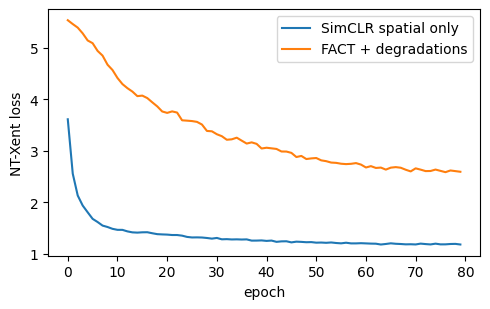

note: losses are not directly comparable across modes (the FACT task is harder); judge by the probe below.


In [10]:
plt.figure(figsize=(5, 3.2))
plt.plot(loss_spatial, label="SimCLR spatial only"); plt.plot(loss_fact, label="FACT + degradations")
plt.xlabel("epoch"); plt.ylabel("NT-Xent loss"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curves.png", dpi=130); plt.show()
print("note: losses are not directly comparable across modes (the FACT task is harder); judge by the probe below.")

## 4. Evaluation: frozen-feature linear probe, few-label regime
Binary `Disease_Risk` on the held-out 20%; labeled examples per class drawn from the training split only; 5 seeds.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

@torch.no_grad()
def feats(enc, imagenet=False):
    enc.eval().to(dev); out = []
    for i in range(0, len(Xg), 256):
        xb = Xg[i:i + 256].float() / 255
        if imagenet: xb = (xb - mean) / std
        out.append(enc(xb).float().cpu())
    return torch.cat(out).numpy()

torch.manual_seed(SEED)
rand = resnet18(weights=None); rand.fc = nn.Identity()
inet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); inet.fc = nn.Identity()

feat_sets = {
    "random init": feats(rand),
    "ImageNet": feats(inet, imagenet=True),
    "SimCLR (spatial)": feats(enc_spatial),
    "SimCLR + FACT (ours)": feats(enc_fact),
}

tr, te = tr_idx.numpy(), te_idx.numpy()
ytr, yte = y[tr_idx].numpy(), y[te_idx].numpy()
rows = []
for name, Fm in feat_sets.items():
    Ftr, Fte = Fm[tr], Fm[te]
    for n in [10, 25, 50, "all"]:
        for seed in range(5 if n != "all" else 1):
            rng = np.random.RandomState(seed)
            sel = np.arange(len(Ftr)) if n == "all" else np.concatenate(
                [rng.choice(np.where(ytr == c)[0], n, replace=False) for c in (0, 1)])
            sc = StandardScaler().fit(Ftr[sel])
            clf = LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced").fit(sc.transform(Ftr[sel]), ytr[sel])
            pr = clf.predict_proba(sc.transform(Fte))[:, 1]
            rows.append(dict(encoder=name, n_per_class=str(n), seed=seed,
                             auroc=roc_auc_score(yte, pr), bal_acc=balanced_accuracy_score(yte, pr > 0.5)))
res = pd.DataFrame(rows)
res.to_csv(f"{OUT_DIR}/probe_results.csv", index=False)
summary = res.groupby(["encoder", "n_per_class"]).agg(auroc=("auroc", "mean"), auroc_std=("auroc", "std"),
                                                       bal_acc=("bal_acc", "mean")).round(3).reset_index()
tab = summary.pivot(index="encoder", columns="n_per_class", values="auroc")[["10", "25", "50", "all"]]
print("Mean AUROC by labeled examples per class:"); print(tab)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 115MB/s]


Mean AUROC by labeled examples per class:
n_per_class              10     25     50    all
encoder                                         
ImageNet              0.645  0.667  0.692  0.757
SimCLR (spatial)      0.587  0.589  0.619  0.692
SimCLR + FACT (ours)  0.592  0.598  0.632  0.744
random init           0.582  0.611  0.649  0.736


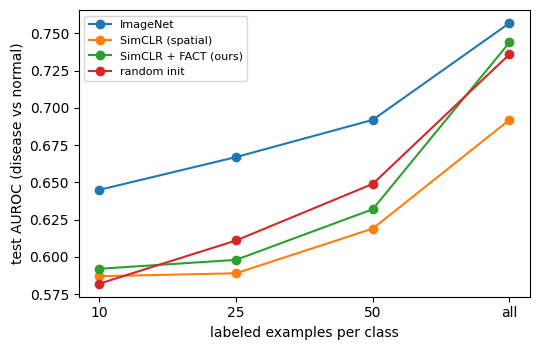

# Preliminary results (RFMiD, 128 px, ResNet-18, 80 epochs)

Linear probe, binary Disease_Risk, held-out 20%, mean test AUROC over 5 seeds.

```
n_per_class              10     25     50    all
encoder                                         
ImageNet              0.645  0.667  0.692  0.757
SimCLR (spatial)      0.587  0.589  0.619  0.692
SimCLR + FACT (ours)  0.592  0.598  0.632  0.744
random init           0.582  0.611  0.649  0.736
```

Preliminary: short schedule, single dataset, binary proxy task.



In [12]:
plt.figure(figsize=(5.5, 3.6))
order = ["10", "25", "50", "all"]
for name in tab.index:
    plt.plot(order, tab.loc[name, order], marker="o", label=name)
plt.xlabel("labeled examples per class"); plt.ylabel("test AUROC (disease vs normal)")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/probe_auroc.png", dpi=130); plt.show()

with open(f"{OUT_DIR}/RESULTS.md", "w") as f:
    f.write("# Preliminary results (RFMiD, 128 px, ResNet-18, %d epochs)\n\n" % EPOCHS)
    f.write("Linear probe, binary Disease_Risk, held-out 20%, mean test AUROC over 5 seeds.\n\n```\n")
    f.write(tab.to_string()); f.write("\n```\n\nPreliminary: short schedule, single dataset, binary proxy task.\n")
print(open(f"{OUT_DIR}/RESULTS.md").read())